# Lab 3 – Classifying Ticket Escalation

Goal: build and compare binary classifiers that predict whether a support ticket gets escalated, then choose a metric and threshold based on what each kind of mistake costs.

Target: `escalated` (1 = escalated, 0 = not escalated)

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("classification_escalation.csv")

print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [3]:
# Missing values per column
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1)
})
display(missing)
print("Rows with at least one missing value:", df.isna().any(axis=1).sum())

,missing_count,missing_pct
complexity_score,0,0.0
team_experience_years,31,3.4
priority,18,2.0
channel,0,0.0
customer_tenure_months,22,2.4
escalated,0,0.0


Rows with at least one missing value: 68


In [4]:
# Target prevalence (counts)
print(df["escalated"].value_counts())

escalated
0    714
1    186
Name: count, dtype: int64


### Why this is a classification task

The target `escalated` takes only two values, 0 or 1, so we are predicting a category rather than a quantity. That makes it binary classification, not regression.

**Positive class = 1 (escalated).** These are the tickets we want the model to find. About 20.7% of tickets are escalated and 79.3% are not, so the classes are imbalanced.

## 3. Train/test split

In [5]:
X = df.drop(columns="escalated")
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Escalation rate - train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))
print("Escalated tickets in test set:", y_test.sum())

Train: (675, 5)  Test: (225, 5)
Escalation rate - train: 0.207  test: 0.204
Escalated tickets in test set: 46


`stratify=y` keeps the escalation rate (about 20.7%) the same in both sets.

## 4. Preprocessing pipelines

In [6]:
numeric_features = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_features = ["priority", "channel"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

Putting the imputer and scaler inside a pipeline means the medians, most-frequent values and scaling are learned from the training data only. That keeps information from the test set out of the model (no data leakage).

## 5. Fit the four models

In [7]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    print("Fitted:", name)

Fitted: Majority baseline
Fitted: Logistic regression
Fitted: LDA
Fitted: k-NN (k=15)


## 6. Model comparison table

In [8]:
rows = []
for name, pipe in fitted.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
display(results)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,0.500
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


In [9]:
# Full classification report for logistic regression
log_reg = fitted["Logistic regression"]
print(classification_report(y_test, log_reg.predict(X_test),
                            target_names=["Not escalated", "Escalated"], zero_division=0))

               precision    recall  f1-score   support

Not escalated       0.83      0.98      0.90       179
    Escalated       0.75      0.20      0.31        46

     accuracy                           0.82       225
    macro avg       0.79      0.59      0.60       225
 weighted avg       0.81      0.82      0.78       225



All four models output probabilities, so ROC-AUC is available for each. The baseline always predicts "not escalated", so its AUC is 0.5 and its precision, recall and F1 are 0.

## 7. Confusion matrix and ROC curve (logistic regression)

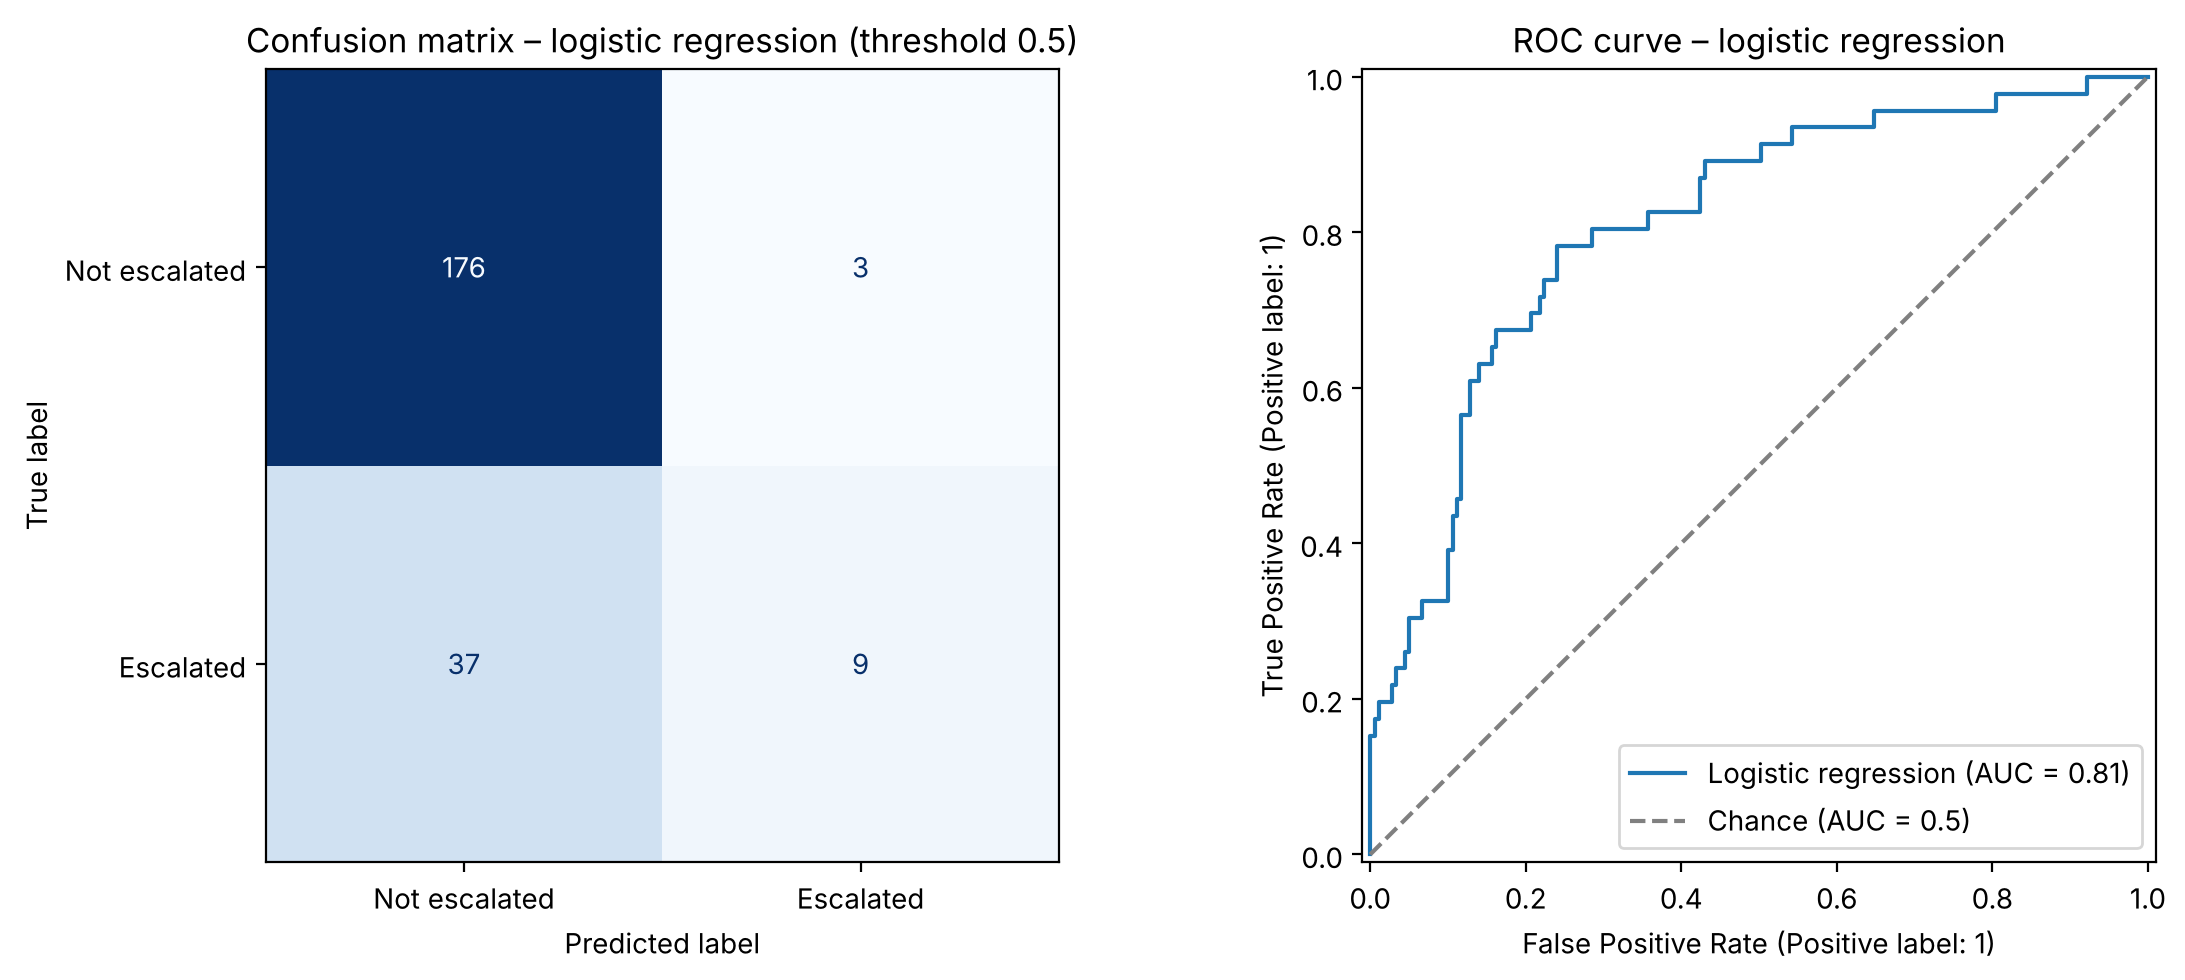

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    log_reg, X_test, y_test,
    display_labels=["Not escalated", "Escalated"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Confusion matrix – logistic regression (threshold 0.5)")

RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=axes[1], name="Logistic regression")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance (AUC = 0.5)")
axes[1].set_title("ROC curve – logistic regression")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 8. Threshold table and cost calculation

Cost function: **cost = 5 × FN + 1 × FP**. Missing a real escalation (FN) is treated as five times worse than flagging a ticket that didn't need it (FP).

In [11]:
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_rows = []
for t in thresholds:
    y_pred_t = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    threshold_rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, y_pred_t, zero_division=0),
        "Recall": recall_score(y_test, y_pred_t),
        "F1": f1_score(y_test, y_pred_t, zero_division=0),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Cost (5×FN + FP)": 5 * fn + fp,
    })

threshold_table = pd.DataFrame(threshold_rows).round(3)
display(threshold_table)

best = threshold_table.loc[threshold_table["Cost (5×FN + FP)"].idxmin()]
print(f"Lowest cost threshold: {best['Threshold']}  (cost = {int(best['Cost (5×FN + FP)'])})")

,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Cost (5×FN + FP)
0,0.2,0.429,0.783,0.554,36,48,10,131,98
1,0.3,0.549,0.609,0.577,28,23,18,156,113
2,0.4,0.571,0.261,0.358,12,9,34,170,179
3,0.5,0.750,0.196,0.310,9,3,37,176,188
4,0.6,1.000,0.065,0.122,3,0,43,179,215
5,0.7,0.000,0.000,0.000,0,0,46,179,230


Lowest cost threshold: 0.2  (cost = 98)


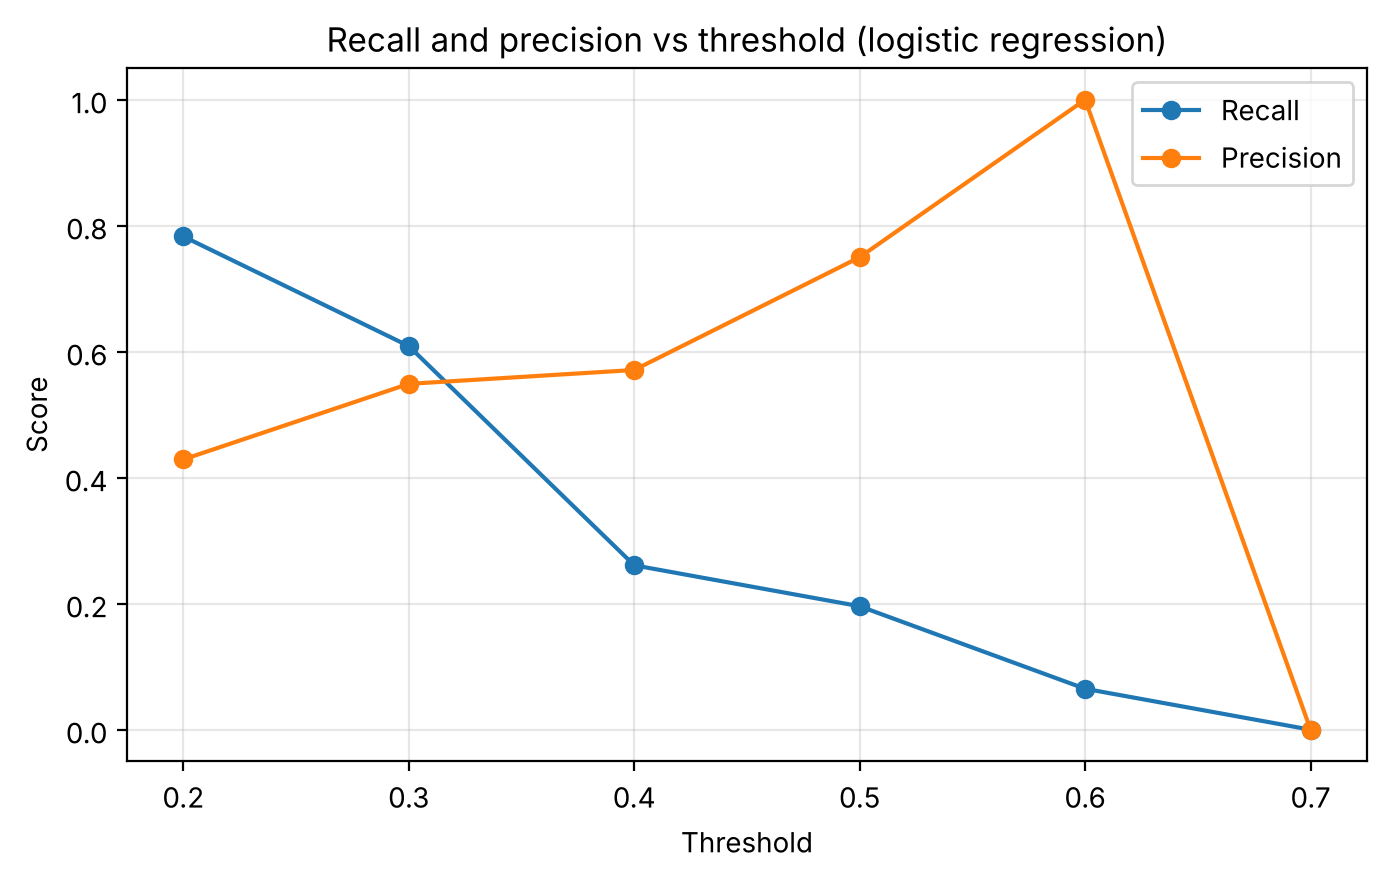

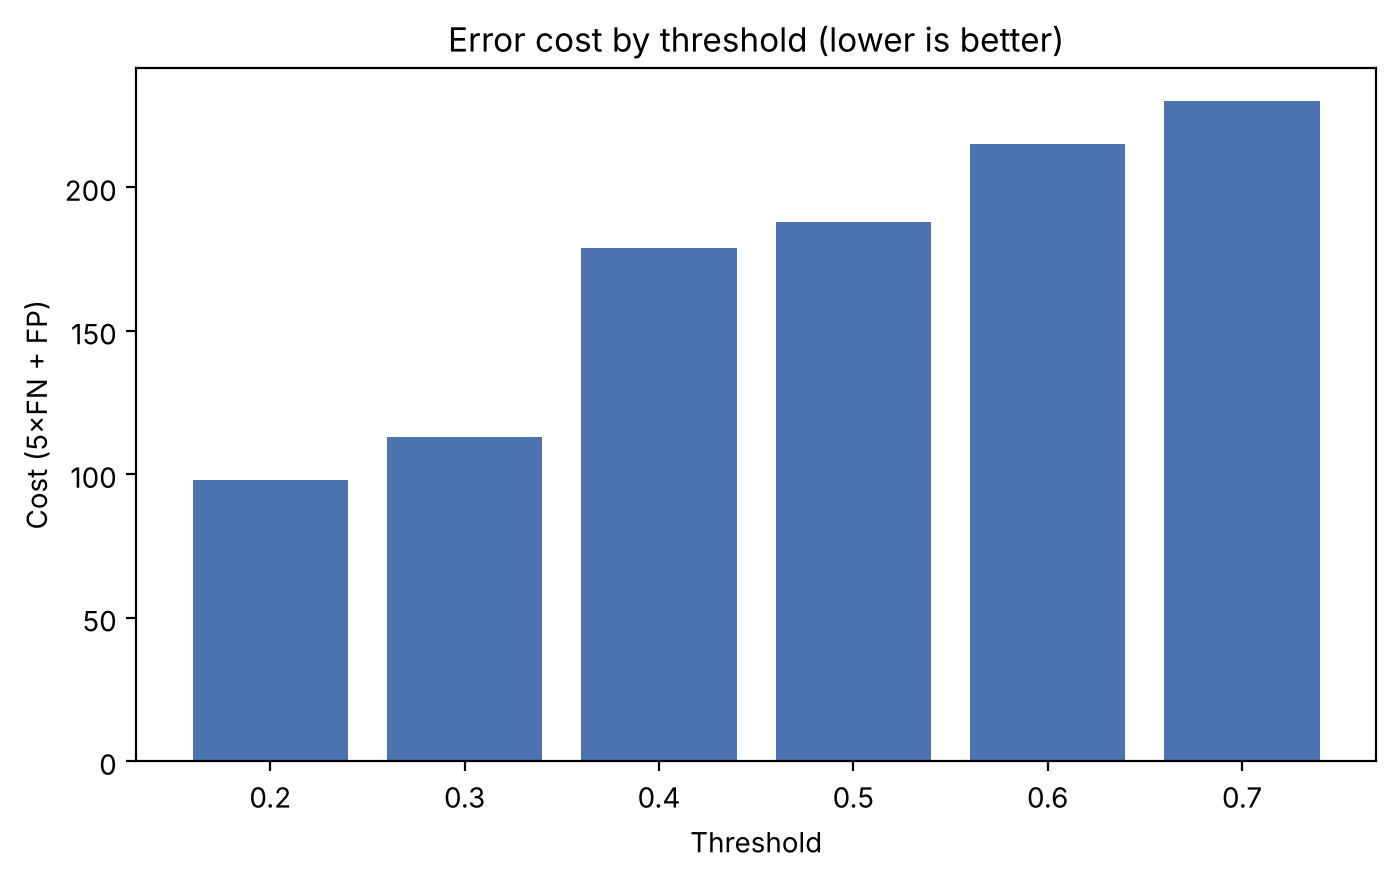

In [12]:
# Recall, precision and cost across thresholds
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(threshold_table["Threshold"], threshold_table["Recall"], marker="o", label="Recall")
ax1.plot(threshold_table["Threshold"], threshold_table["Precision"], marker="o", label="Precision")
ax1.set_xlabel("Threshold")
ax1.set_ylabel("Score")
ax1.set_title("Recall and precision vs threshold (logistic regression)")
ax1.legend()
ax1.grid(alpha=0.3)
plt.show()

fig, ax2 = plt.subplots(figsize=(8, 4.5))
ax2.bar(threshold_table["Threshold"].astype(str), threshold_table["Cost (5×FN + FP)"], color="#4C72B0")
ax2.set_xlabel("Threshold")
ax2.set_ylabel("Cost (5×FN + FP)")
ax2.set_title("Error cost by threshold (lower is better)")
plt.show()

At 0.70 the model flags no tickets at all, so precision is undefined (0 of 0) and is reported as 0. Recall falls as the threshold rises and precision mostly climbs, which is the usual trade-off.

## 9. Stratified 5-fold cross-validation and tuning k for k-NN

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier())])
param_grid = {"model__n_neighbors": [5, 9, 15, 21, 31]}

grid = GridSearchCV(knn_pipe, param_grid, scoring="f1", cv=cv)
grid.fit(X_train, y_train)

cv_table = pd.DataFrame(grid.cv_results_)[["param_model__n_neighbors", "mean_test_score", "std_test_score"]]
cv_table.columns = ["k", "Mean CV F1", "Std CV F1"]
display(cv_table.round(3))
print("Best k:", grid.best_params_["model__n_neighbors"], " best mean CV F1:", round(grid.best_score_, 3))

,k,Mean CV F1,Std CV F1
0,5,0.243,0.095
1,9,0.198,0.065
2,15,0.160,0.065
3,21,0.146,0.056
4,31,0.112,0.040


Best k: 5  best mean CV F1: 0.243


In [14]:
# Test-set performance of the tuned k-NN
best_knn = grid.best_estimator_
y_pred_knn = best_knn.predict(X_test)
print("Tuned k-NN test F1:", round(f1_score(y_test, y_pred_knn), 3),
      " recall:", round(recall_score(y_test, y_pred_knn), 3),
      " precision:", round(precision_score(y_test, y_pred_knn, zero_division=0), 3))

Tuned k-NN test F1: 0.203  recall: 0.13  precision: 0.462


In [15]:
# Same 5-fold CV for the other models, for a fairer comparison than one test split
cv_rows = []
for name in ["Logistic regression", "LDA", "k-NN (k=15)"]:
    pipe = Pipeline([("prep", preprocessor), ("model", models[name])])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "recall", "precision", "roc_auc"])
    cv_rows.append({
        "Model": name,
        "CV F1": scores["test_f1"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
    })
display(pd.DataFrame(cv_rows).set_index("Model").round(3))

,CV F1,CV Recall,CV Precision,CV ROC-AUC
Model,,,,
Logistic regression,0.248,0.164,0.539,0.744
LDA,0.266,0.179,0.554,0.743
k-NN (k=15),0.160,0.100,0.458,0.681


## 10. Extra check: choosing the threshold without touching the test set

In [16]:
from sklearn.model_selection import cross_val_predict

lr_pipe = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])
oof_prob = cross_val_predict(lr_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in [0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (oof_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({"Threshold": t, "Recall": recall_score(y_train, pred), "FP": fp, "FN": fn, "Cost (5×FN + FP)": 5 * fn + fp})
display(pd.DataFrame(rows).round(3))

,Threshold,Recall,FP,FN,Cost (5×FN + FP)
0,0.15,0.807,245,27,380
1,0.20,0.693,176,43,391
2,0.30,0.486,102,72,462
3,0.40,0.329,47,94,517
4,0.50,0.164,20,117,605
5,0.60,0.043,7,134,677
6,0.70,0.021,3,137,688


These are out-of-fold predictions on the training set, so the threshold is picked without looking at the test set. 0.15 and 0.20 come out cheapest, which agrees with the test-set result and with the theoretical threshold of 1/6 derived in Question 6.

## 11. Answers to the questions

### Q1. Why is accuracy alone potentially misleading?

Only 20.7% of tickets are escalated. A model that predicts "not escalated" for every ticket scores 79.6% accuracy on the test set while catching none of the 46 escalations. Logistic regression at the default 0.5 threshold looks only a little better at 82.2% accuracy, yet it misses 37 of the 46 escalated tickets (recall 0.196). Accuracy counts every correct prediction equally, so with imbalanced classes it is dominated by the easy majority class and hides how badly the model does on the class we care about. It also ignores the fact that a missed escalation costs more than a false alarm.

### Q2. Which classifier has the strongest recall? Which has the strongest precision/F1?

At the default 0.5 threshold, logistic regression and LDA tie on every threshold-based metric: recall 0.196, precision 0.75 and F1 0.310 (each finds 9 of the 46 escalations with 3 false alarms). Logistic regression is slightly ahead on ROC-AUC (0.811 vs 0.809). k-NN with k=15 is weaker on all three (recall 0.087, precision 0.50, F1 0.148), and the baseline scores 0.

In 5-fold cross-validation on the training set LDA is marginally ahead (CV F1 0.266 vs 0.248), so the two linear models are effectively equal. Recall also depends heavily on the threshold: lowering logistic regression's threshold to 0.20 raises its recall to 0.783.

### Q3. What changes when the threshold is lowered?

More tickets get flagged as escalated. True positives rise and false negatives fall, so recall goes up, but false positives rise too, so precision goes down. For logistic regression, going from 0.50 to 0.20 moves recall from 0.196 to 0.783 and cuts missed escalations from 37 to 10, while false positives grow from 3 to 48 and precision drops from 0.75 to 0.43. F1 improves here (0.310 to 0.554) because the model was far too conservative at 0.5.

### Q4. Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic?

**0.20**, with a cost of 98 (10 FN × 5 + 48 FP). The next best is 0.30 at 113, and the default 0.50 costs 188. Predicting "not escalated" for everything would cost 230.

The estimate is optimistic because the threshold was chosen by looking at the test set. Once the test set is used to make a choice, it stops being an unbiased estimate of future performance; we picked whichever threshold happened to suit these 225 tickets. With only 46 escalated tickets, a few tickets moving across the line changes the cost noticeably (the theoretical threshold of 1/6 gives 109 on this same test set, for example). If the test set is reused again and again for tuning, the model and threshold slowly overfit to it. The threshold should be chosen with cross-validation on the training data (Section 10) or a separate validation set, and the test set used once at the end.

### Q5. Prior, likelihood, posterior and evidence in the ticket scenario

Bayes' rule: P(escalated | x) = P(x | escalated) × P(escalated) / P(x)

- **Prior, P(escalated)**: the escalation rate before we look at the ticket, about 0.207 in this data.
- **Likelihood, P(x | escalated)**: how likely we are to see this particular ticket profile (for example complexity 9, 1.5 years of team experience, phone channel) among tickets that were escalated.
- **Evidence, P(x)**: how likely that profile is across all tickets, escalated or not: P(x | esc)·P(esc) + P(x | not esc)·P(not esc). It scales the result so the probabilities sum to 1.
- **Posterior, P(escalated | x)**: the updated probability that this specific ticket will be escalated once its features are known. This is what we compare against the threshold.

Illustrative numbers: if P(x | esc) = 0.10 and P(x | not esc) = 0.02, the evidence is 0.10 × 0.207 + 0.02 × 0.793 = 0.0366 and the posterior is 0.0207 / 0.0366 ≈ 0.57. A ticket that looks typical of escalations raises the probability from the 21% prior to 57%.

LDA works this way directly: it models P(x | class) as a Gaussian for each class and applies Bayes' rule. Logistic regression skips the likelihood and models the posterior directly.

### Q6. Expected cost with P(escalated | x) = 0.30, C_FP = 1, C_FN = 5

- **Escalate**: the only possible mistake is a false positive, which happens if the ticket would not have escalated (probability 0.70).
  Expected cost = 0.70 × 1 = **0.70**
- **Do not escalate**: the only possible mistake is a false negative (probability 0.30).
  Expected cost = 0.30 × 5 = **1.50**

0.70 < 1.50, so the cheaper decision is to escalate, even though the ticket is more likely not to escalate.

**Cost-sensitive threshold.** Escalate when the expected cost of escalating is lower:

(1 − p) × C_FP < p × C_FN
(1 − p) × 1 < 5p
1 < 6p
p > 1/6 ≈ 0.167

In general, t* = C_FP / (C_FP + C_FN) = 1 / (1 + 5) ≈ 0.17. This is why the low threshold of 0.20 did best in the cost table, and why the default 0.5 (which assumes equal costs) is a poor fit here.

### Q7. Which model would you recommend for deployment, and what further checks are required?

Logistic regression with a threshold of about 0.20. It matches LDA on performance, has the best test ROC-AUC (0.811), produces probabilities we can threshold according to cost, and its coefficients are easy to explain (higher complexity raises escalation odds; more team experience lowers them).

Further checks before deployment:
- Validate the threshold on fresh data (a new hold-out set or a time-based split), not the test set used for tuning.
- Check calibration, so that a predicted 0.30 really means about a 30% escalation rate.
- Compare error rates across channels and priority levels to make sure some groups of tickets are not missed more often.
- Confirm the real cost ratio with the business instead of using the illustrative 5:1.
- Run the model in shadow mode first, then monitor recall, false-alarm volume and data drift over time.

## 12. Recommendation

I recommend deploying the logistic regression model with a decision threshold of 0.20, used as a flag that sends a ticket to a senior team member for review rather than escalating it automatically.

**Model choice.** Logistic regression and LDA gave identical results at the default threshold of 0.5 (accuracy 0.822, precision 0.75, recall 0.196, F1 0.310), and logistic regression had a slightly higher ROC-AUC (0.811 against 0.809). Both clearly beat the majority-class baseline, whose 79.6% accuracy comes entirely from predicting "not escalated" for every ticket. k-NN was the weakest model. After tuning, the best k was 5, and it still reached a cross-validated F1 of only 0.24. I prefer logistic regression to LDA because its coefficients are easy to explain to support managers: higher complexity raises the odds of escalation and more team experience lowers them.

**Threshold and error costs.** At 0.5 the model misses 37 of the 46 escalated tickets in the test set. If a missed escalation costs five times as much as an unnecessary review, that is the wrong trade. Lowering the threshold to 0.20 raises recall from 0.20 to 0.78 and cuts the illustrative cost (5×FN + FP) from 188 to 98, at the price of 48 false alarms instead of 3. The decision rule points the same way: with costs of 1 and 5, escalating is cheaper whenever the predicted probability is above 1/6, or about 0.17. Picking the threshold with cross-validation on the training set gave 0.15 and 0.20 as the two cheapest options, so the choice holds up without the test set.

**Limitations.** The test set contains only 46 escalated tickets, so a handful of tickets changing sides moves recall by several points. I compared thresholds on the test set, which makes the cost of 98 optimistic. The data is synthetic, about 7.6% of rows had a missing value filled in by imputation, and an AUC of 0.81 means the model still ranks a fair share of tickets in the wrong order. The 5:1 cost ratio is only illustrative. The real ratio should come from the business, and the threshold should be recalculated if it changes.

**Responsible-use risks.** At 0.20 a flag is wrong more often than it is right (precision 0.43), so staff should treat it as a reason to look closer, never as a verdict. Error rates need to be checked by channel and priority before go-live, because a model can miss escalations for one group of customers more than another while looking fine overall. Staff may also start trusting the score over their own judgement, and if escalation policy or ticket volumes change, the patterns the model learned will drift. I would run it in shadow mode first, compare its flags with real outcomes, and then track recall and false-alarm volume every month.